<a href="https://colab.research.google.com/github/linapioche/nlp-text-summarization/blob/main/01_exploration_samsum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch
print(torch.cuda.is_available())


True


In [3]:
!pip install datasets

In [4]:
from datasets import load_dataset

In [5]:
dataset_samsum=load_dataset("knkarthick/samsum")

README.md:   0%|          | 0.00/4.36k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/9.26M [00:00<?, ?B/s]

validation.csv:   0%|          | 0.00/504k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/522k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/14731 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/818 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/819 [00:00<?, ? examples/s]

In [6]:
print(len(dataset_samsum["test"]))

819


In [7]:
print(len(dataset_samsum["train"]))

14731


In [8]:
print(len(dataset_samsum["validation"]))

818


Après avoir chargé le dataset SAMSum et vérifié la taille de ses trois parties,nous observons quelques exemples au hasard afin de comprendre la nature des données (style des dialogues, forme des résumés) avant de décider des étapes de prétraitement.

In [9]:
import random

random.seed(42)  # mêmes exemples à chaque exécution

n = len(dataset_samsum["train"])        # nombre de lignes du train
indices = random.sample(range(n), 5)

for i in indices:
    ligne = dataset_samsum["train"][i]  # un dictionnaire : id, dialogue, summary
    print("DIALOGUE :")
    print(ligne["dialogue"])
    print("RÉSUMÉ :")
    print(ligne["summary"])
    print("-" * 50)



DIALOGUE :
David: The new movie of Jonhy English has come out, have you seen it?
Patricia: No but I have been meaning to go tough. I heard it's hilarious.
David: Rowan Atkison is just awesome, love that guy! In Mr. Bean I would just laugh so hard ahaha
Patricia: Me too 😂 I couldn't watch some scenes sometimes cause they would make me nervous from all the constant crap he did ahhaha
David: ahahaa xD  Anyway.. wanna go to the 21:40 session today? I ain't got much going on so..
Patricia: Sure! Where are you having dinner?
David: Was thinking of just ordering a pizza, you have any ideas?
Patricia: There's a new Mexican place and they do take out's, want me to grab something and meet you at your place?
David: Oh that's what I'm talking about! Bring me 2 chicken burritos and nachoooos with guacamole.
Patricia: Anything else for the little boy? ahaha xD
David: While you're at it a coke would do 😂
Patricia: Jesus.. x) Leaving my place now, cya in a bit.
RÉSUMÉ :
Patricia and David are going to

Ces exemples montrent des dialogues informels (abréviations, fautes, émojis, balises comme <file_video>) de longueurs très variables, résumés à la troisième personne. Nous allons maintenant mesurer les longueurs des dialogues et des résumés pour choisir les paramètres de troncature, puis construire le    prétraitement et le vocabulaire

In [10]:
import numpy as np

# Lignes vides ou manquantes, sur les 3 parties
for nom_partie in ["train", "validation", "test"]:
    partie = dataset_samsum[nom_partie]
    vides_dial = sum(1 for t in partie["dialogue"] if t is None or t.strip() == "")
    vides_resume = sum(1 for t in partie["summary"] if t is None or t.strip() == "")
    print(nom_partie, "| dialogues vides :", vides_dial, "| résumés vides :", vides_resume)

# Longueurs en nombre de mots (sur le train)
train = dataset_samsum["train"]
long_dial = [len(t.split()) for t in train["dialogue"]]
long_resume = [len(t.split()) for t in train["summary"]]

for nom, longueurs in [("dialogues", long_dial), ("résumés", long_resume)]:
    print(nom,
          "| moyenne :", round(np.mean(longueurs), 1),
          "| médiane :", np.median(longueurs),
          "| max :", np.max(longueurs),
          "| 95e percentile :", np.percentile(longueurs, 95))

train | dialogues vides : 0 | résumés vides : 0
validation | dialogues vides : 0 | résumés vides : 0
test | dialogues vides : 0 | résumés vides : 0
dialogues | moyenne : 93.8 | médiane : 73.0 | max : 803 | 95e percentile : 237.0
résumés | moyenne : 20.3 | médiane : 18.0 | max : 64 | 95e percentile : 43.0


**Vérification des données et longueurs des textes**

Nous avons vérifié que les trois parties (train : 14 731, validation : 818, test : 819) ne contiennent aucun dialogue ni résumé vide. Nous avons ensuite mesuré la longueur des textes en nombre de mots sur le train : les dialogues font en moyenne 93,8 mots (médiane 73, maximum 803, 95e percentile 237) et les résumés 20,3 mots (médiane 18, maximum 64, 95e percentile 43).

Les dialogues sont donc environ 4 à 5 fois plus longs que les résumés, et les très longs textes sont rares. Les textes sont tronqués au 95e percentile de leur longueur (240 mots pour les dialogues, 45 pour les résumés) : le modèle a besoin de séquences de taille fixe, et ce seuil garde 95 % des textes entiers sans gaspiller de calcul sur de rares dialogues très longs.

In [11]:
import re

# Le "motif" décrit ce qu'on veut extraire du texte. Trois possibilités, séparées par "|" :
#   1) <[a-z_0-9]+>        -> une balise entière, comme <file_video>
#   2) \w+(?:['’]\w+)?     -> un mot, avec son apostrophe éventuelle (don't, i'm)
#   3) [^\w\s]             -> un seul signe de ponctuation (. , ? ! : 😂 ...)
MOTIF = re.compile(r"<[a-z_0-9]+>|\w+(?:['’]\w+)?|[^\w\s]")

def tokenize(texte):
    texte = texte.lower()          # décision 1 : tout en minuscules
    return MOTIF.findall(texte)    # on récupère tous les morceaux qui correspondent au motif

# Test sur une phrase inspirée de tes exemples
print(tokenize("Patricia: Me too 😂 I couldn't watch <file_video>, ok?"))

['patricia', ':', 'me', 'too', '😂', 'i', "couldn't", 'watch', '<file_video>', ',', 'ok', '?']


In [12]:
#test suivant
tokenize(dataset_samsum["train"][0]["dialogue"])

['amanda',
 ':',
 'i',
 'baked',
 'cookies',
 '.',
 'do',
 'you',
 'want',
 'some',
 '?',
 'jerry',
 ':',
 'sure',
 '!',
 'amanda',
 ':',
 "i'll",
 'bring',
 'you',
 'tomorrow',
 ':',
 '-',
 ')']

La fonction de tokenisation passe le texte en minuscules, conserve les balises (<file_video>) et les mots avec apostrophe (i'll) comme tokens uniques, et sépare chaque signe de ponctuation. Les émoticônes textuelles comme :-) sont découpées en plusieurs tokens, ce qui constitue une limite mineure.

In [13]:
from collections import Counter

# Un compteur par côté : un pour les dialogues (entrée), un pour les résumés (sortie).
# Un Counter, c'est un dictionnaire {token: nombre d'apparitions}.
compteur_dial = Counter()
compteur_resume = Counter()

# On ne regarde QUE le train (jamais validation ni test).
for texte in dataset_samsum["train"]["dialogue"]:
    compteur_dial.update(tokenize(texte))   # on ajoute les tokens de ce dialogue au compteur

for texte in dataset_samsum["train"]["summary"]:
    compteur_resume.update(tokenize(texte))

# Statistiques
for nom, compteur in [("dialogues", compteur_dial), ("résumés", compteur_resume)]:
    total = len(compteur)                                          # nb de tokens DIFFÉRENTS
    uniques = sum(1 for n in compteur.values() if n == 1)          # vus une seule fois
    print(nom, "| tokens différents :", total, "| vus 1 seule fois :", uniques)
    print("   10 plus fréquents :", compteur.most_common(10))

dialogues | tokens différents : 30794 | vus 1 seule fois : 12016
   10 plus fréquents : [(':', 177835), ('.', 73097), (',', 53151), ('i', 44232), ('?', 43003), ('you', 39122), ('!', 33391), ('the', 31583), ('to', 29226), ('a', 22340)]
résumés | tokens différents : 17462 | vus 1 seule fois : 8113
   10 plus fréquents : [('.', 30449), ('to', 11618), ('the', 10756), ('and', 10146), ('a', 7478), ('is', 6850), ('will', 6743), (',', 5979), ('for', 4678), ('in', 4172)]


**Analyse des fréquences et choix du seuil du vocabulaire**

Après avoir défini la fonction de tokenisation (minuscules, ponctuation séparée, balises et mots avec apostrophe conservés), nous comptons la fréquence de chaque token sur le train uniquement, afin de ne rien apprendre des données de validation et de test. Nous construisons deux compteurs distincts : un pour les dialogues (entrée de l’encodeur) et un pour les résumés (sortie du décodeur), car leurs distributions de mots diffèrent : les dialogues contiennent beaucoup de :, de i et de you, tandis que les résumés, écrits à la troisième personne, contiennent surtout will, is et to.

Les résultats montrent une distribution très déséquilibrée: 30 794 tokens différents dans les dialogues, dont 12 016 n’apparaissent qu’une seule fois, et 17 462 dans les résumés, dont 8 113 n’apparaissent qu’une seule fois. Un token vu une seule fois ne fournit au modèle qu’un exemple pour apprendre son sens et alourdit inutilement les couches d’embedding et de sortie.

Nous fixons donc un seuil de fréquence minimale N = 2 : seuls les tokens vus au moins deux fois dans le train sont conservés, les autres sont remplacés par <UNK>. Le prix à payer est que certains mots rares, notamment des prénoms, seront perdus.

Étape suivante : construction des deux vocabulaires (avec les tokens spéciaux <PAD>, <UNK>, <SOS>, <EOS>), puis conversion des textes en identifiants numériques.

In [14]:
# Les 4 tokens spéciaux, dans cet ordre : leur numéro est leur position (0, 1, 2, 3)
TOKENS_SPECIAUX = ["<PAD>", "<UNK>", "<SOS>", "<EOS>"]
SEUIL = 2   # N = 2 : un token doit apparaître au moins 2 fois dans le train

def construire_vocab(compteur, seuil):
    # On commence par les tokens spéciaux
    liste = list(TOKENS_SPECIAUX)
    # Puis on ajoute chaque token assez fréquent (les plus fréquents d'abord)
    for token, freq in compteur.most_common():
        if freq >= seuil:
            liste.append(token)
    # token -> numéro (pour encoder un texte en nombres)
    token_vers_id = {token: i for i, token in enumerate(liste)}
    # numéro -> token (pour relire les résumés générés)
    id_vers_token = {i: token for token, i in token_vers_id.items()}
    return token_vers_id, id_vers_token

# Un vocabulaire par côté, construits UNIQUEMENT à partir des compteurs du train
vocab_dial, id_dial = construire_vocab(compteur_dial, SEUIL)
vocab_resume, id_resume = construire_vocab(compteur_resume, SEUIL)

print("Vocabulaire dialogues :", len(vocab_dial))
print("Vocabulaire résumés   :", len(vocab_resume))
print("Spéciaux :", {t: vocab_dial[t] for t in TOKENS_SPECIAUX})

# Test : un mot connu et un mot inconnu
print(vocab_dial.get("amanda", vocab_dial["<UNK>"]))
print(vocab_dial.get("mot_inventé_xyz", vocab_dial["<UNK>"]))

Vocabulaire dialogues : 18782
Vocabulaire résumés   : 9353
Spéciaux : {'<PAD>': 0, '<UNK>': 1, '<SOS>': 2, '<EOS>': 3}
452
1


Nous construisons deux vocabulaires à partir du train uniquement : un pour les dialogues (entrée de l’encodeur) et un pour les résumés (sortie du décodeur). Chacun commence par les tokens spéciaux <PAD> (0), <UNK> (1), <SOS> (2) et <EOS> (3), suivis des tokens apparaissant au moins deux fois dans le train, classés du plus fréquent au moins fréquent. On obtient 18 782 entrées pour les dialogues et 9 353 pour les résumés.

Tout mot absent du vocabulaire est encodé par <UNK>, comme le montre le test final : un mot connu (amanda) reçoit son propre numéro, tandis qu’un mot inventé reçoit 1. Un dictionnaire inverse (numéro vers token) est également construit pour relire les résumés générés.

Étape suivante : conversion des textes en séquences de numéros (troncature, ajout de <SOS> et <EOS> sur les résumés, padding par lots), puis définition du modèle encodeur-décodeur.

Chaque dialogue est tokenisé, tronqué à 300 tokens, puis converti en numéros grâce au vocabulaire des dialogues (<UNK> pour les mots inconnus). Chaque résumé est tronqué à 48 tokens et encadré par <SOS> et <EOS>. Les données sont ensuite regroupées en lots de 64 : dans chaque lot, les textes courts sont complétés par des <PAD> jusqu’à la longueur du plus long. Les vraies longueurs sont conservées pour que l’encodeur ignore le remplissage.

In [15]:
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import numpy as np

PAD, UNK, SOS, EOS = 0, 1, 2, 3
MAX_SRC = 300   # longueur max d'un dialogue, en tokens (la ponctuation compte)
MAX_TGT = 50    # longueur max d'un résumé, <SOS> et <EOS> compris

def encoder_dialogue(texte):
    tokens = tokenize(texte)[:MAX_SRC]                 # troncature
    return [vocab_dial.get(t, UNK) for t in tokens]    # mot -> numéro (UNK si inconnu)

def encoder_resume(texte):
    tokens = tokenize(texte)[:MAX_TGT - 2]             # 2 places gardées pour SOS et EOS
    return [SOS] + [vocab_resume.get(t, UNK) for t in tokens] + [EOS]

class SamsumDataset(Dataset):
    def __init__(self, partie):
        self.src = [encoder_dialogue(d) for d in partie["dialogue"]]
        self.tgt = [encoder_resume(s) for s in partie["summary"]]
    def __len__(self):
        return len(self.src)
    def __getitem__(self, i):
        return torch.tensor(self.src[i]), torch.tensor(self.tgt[i])

def collate(batch):
    # Complète chaque lot avec des <PAD> pour que tous les textes aient la même longueur
    src, tgt = zip(*batch)
    src_len = torch.tensor([len(s) for s in src])      # vraies longueurs (sans PAD)
    src = pad_sequence(src, batch_first=True, padding_value=PAD)
    tgt = pad_sequence(tgt, batch_first=True, padding_value=PAD)
    return src, src_len, tgt

BATCH = 64
train_loader = DataLoader(SamsumDataset(dataset_samsum["train"]), batch_size=BATCH, shuffle=True, collate_fn=collate)
val_loader   = DataLoader(SamsumDataset(dataset_samsum["validation"]), batch_size=BATCH, collate_fn=collate)
test_loader  = DataLoader(SamsumDataset(dataset_samsum["test"]), batch_size=BATCH, collate_fn=collate)

# Vérification : 95e percentile des longueurs en tokens, pour valider MAX_SRC et MAX_TGT
print("dialogues p95 :", np.percentile([len(tokenize(d)) for d in dataset_samsum["train"]["dialogue"]], 95))
print("résumés  p95 :", np.percentile([len(tokenize(s)) for s in dataset_samsum["train"]["summary"]], 95))
src, src_len, tgt = next(iter(train_loader))
print(src.shape, tgt.shape)

dialogues p95 : 302.0
résumés  p95 : 49.0
torch.Size([64, 300]) torch.Size([64, 50])


**Vérification des longueurs en tokens et des lots**

Les longueurs mesurées plus haut étaient en mots. Après tokenisation, la ponctuation devient des tokens à part entière, donc les séquences sont plus longues. Le 95e percentile calculé sur le train est de 302 tokens pour les dialogues et 49 tokens pour les résumés. Nous fixons donc la longueur maximale à 300 tokens pour les dialogues et à 50 tokens pour les résumés, <SOS> et <EOS> compris (48 tokens de texte). Environ 5 % des dialogues et un peu plus de 5 % des résumés sont légèrement tronqués, ce qui est une limite assumée.

Les données sont regroupées en lots de 64 (compromis courant entre stabilité du gradient, vitesse et mémoire GPU). Dans chaque lot, les textes sont complétés par des <PAD> jusqu’à la longueur du plus long. Un lot a la forme [64, 300] pour les dialogues et [64, 50] pour les résumés : 64 exemples, 300 et 50 positions.

**Architecture : encodeur-décodeur GRU (baseline sans attention)**

L’encodeur transforme les numéros en vecteurs (embedding de dimension 128), puis un GRU à une couche, unidirectionnel, de dimension cachée 256, lit tout le dialogue. Son dernier état caché est la représentation du dialogue. Le décodeur initialise son état avec cette représentation et génère le résumé mot par mot : à chaque pas, il reçoit le mot précédent, et une couche linéaire produit un score pour chaque mot du vocabulaire des résumés. Pendant l’entraînement, on utilise le teacher forcing avec un ratio de 0,5. Les <PAD> sont ignorés dans la perte et, côté encodeur, grâce à l’empaquetage des séquences.

In [16]:
import torch.nn as nn, random
from torch.nn.utils.rnn import pack_padded_sequence

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)
EMB, HID = 128, 256

class Encoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)   # numéro -> vecteur
        self.gru = nn.GRU(EMB, HID, batch_first=True)
    def forward(self, src, src_len):
        x = self.emb(src)
        packed = pack_padded_sequence(x, src_len.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.gru(packed)       # h : "résumé mental" du dialogue, (1, B, HID)
        return h

class Decoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)
        self.gru = nn.GRU(EMB, HID, batch_first=True)
        self.out = nn.Linear(HID, vocab_size)     # un score par mot du vocabulaire
    def forward(self, token, h):                  # token : (B,) le mot précédent
        x = self.emb(token).unsqueeze(1)
        o, h = self.gru(x, h)
        return self.out(o.squeeze(1)), h

class Seq2Seq(nn.Module):
    def __init__(self, enc, dec):
        super().__init__()
        self.enc, self.dec = enc, dec
    def forward(self, src, src_len, tgt, tf_ratio=0.5):
        h = self.enc(src, src_len)                # état initial du décodeur
        token = tgt[:, 0]                         # <SOS>
        sorties = []
        for t in range(1, tgt.size(1)):
            logits, h = self.dec(token, h)
            sorties.append(logits)
            # teacher forcing : avec proba tf_ratio, on donne le VRAI mot, sinon la prédiction
            token = tgt[:, t] if random.random() < tf_ratio else logits.argmax(1)
        return torch.stack(sorties, dim=1)        # (B, T-1, taille_vocab)

model = Seq2Seq(Encoder(len(vocab_dial)), Decoder(len(vocab_resume))).to(device)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

Device : cuda
Paramètres : 6597897


Epoch 1 | train 6.239 | val 5.402 | 20s
Epoch 2 | train 5.671 | val 5.031 | 19s
Epoch 3 | train 5.488 | val 4.849 | 21s
Epoch 4 | train 5.317 | val 4.718 | 18s
Epoch 5 | train 5.158 | val 4.615 | 19s


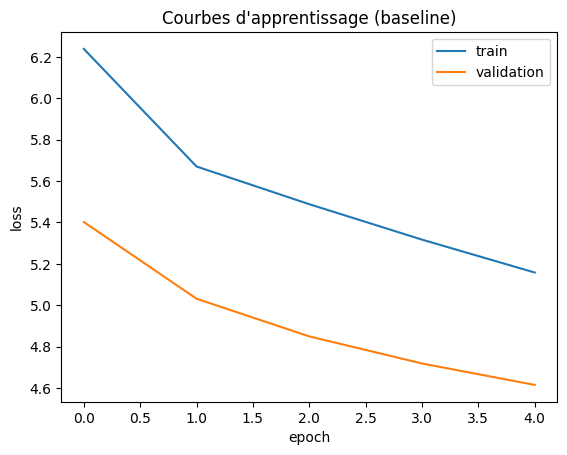

In [17]:
import matplotlib.pyplot as plt, time

criterion = nn.CrossEntropyLoss(ignore_index=PAD)   # ignore les <PAD> dans la perte
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 5
TF_RATIO = 0.5

def run_epoch(loader, train, tf_ratio):
    model.train(train)
    total = 0
    for src, src_len, tgt in loader:
        src, tgt = src.to(device), tgt.to(device)
        with torch.set_grad_enabled(train):
            out = model(src, src_len, tgt, tf_ratio)                 # (B, T-1, V)
            loss = criterion(out.reshape(-1, out.size(-1)), tgt[:, 1:].reshape(-1))
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)    # évite les gradients explosifs
                optimizer.step()
        total += loss.item()
    return total / len(loader)

hist_train, hist_val, meilleur = [], [], float("inf")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr = run_epoch(train_loader, True, TF_RATIO)
    va = run_epoch(val_loader, False, 1.0)       # validation avec teacher forcing total
    hist_train.append(tr); hist_val.append(va)
    if va < meilleur:
        meilleur = va
        torch.save(model.state_dict(), "baseline_gru.pt")   # on garde le meilleur modèle
    print(f"Epoch {epoch} | train {tr:.3f} | val {va:.3f} | {time.time()-t0:.0f}s")

plt.plot(hist_train, label="train"); plt.plot(hist_val, label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Courbes d'apprentissage (baseline)")
plt.show()

**Entraînement**

Le modèle est entraîné avec la perte d’entropie croisée au niveau du token (les <PAD> sont ignorés), l’optimiseur Adam (learning rate 1e-3), un batch de 64, 30 epochs et un teacher forcing de 0,5. Le gradient est limité à une norme de 1. La perte de validation est calculée avec teacher forcing total, et on conserve les poids de l’epoch où elle est minimale.

**Lecture des courbes**

 Les pertes d’entraînement et de validation baissent ensemble, sans remontée de la validation : nous n’observons pas de surapprentissage, et le modèle sous-apprend plutôt tant qu’il n’a pas convergé. La perte de validation est inférieure à celle du train, ce qui s’explique par la différence de protocole : l’entraînement utilise un teacher forcing de 0,5 (le modèle doit parfois s’appuyer sur ses propres prédictions, plus difficile), alors que la validation utilise un teacher forcing total. Les deux courbes ne sont donc pas directement comparables

In [18]:
model = Seq2Seq(Encoder(len(vocab_dial)), Decoder(len(vocab_resume))).to(device)
print("Paramètres baseline :", sum(p.numel() for p in model.parameters()))

Paramètres baseline : 6597897


In [19]:
import torch
print(torch.cuda.is_available())

True


In [20]:
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_packed_sequence

class EncoderAtt(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)
        self.gru = nn.GRU(EMB, HID, batch_first=True)
    def forward(self, src, src_len):
        x = self.emb(src)
        packed = pack_padded_sequence(x, src_len.cpu(), batch_first=True, enforce_sorted=False)
        out, h = self.gru(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))
        return out, h

class Attention(nn.Module):
    def __init__(self):
        super().__init__()
        self.W_dec = nn.Linear(HID, HID, bias=False)
        self.W_enc = nn.Linear(HID, HID, bias=False)
        self.v = nn.Linear(HID, 1, bias=False)
    def forward(self, h_dec, enc_out, mask):
        score = self.v(torch.tanh(self.W_enc(enc_out) + self.W_dec(h_dec).unsqueeze(1))).squeeze(2)
        score = score.masked_fill(~mask, -1e9)
        poids = F.softmax(score, dim=1)
        contexte = torch.bmm(poids.unsqueeze(1), enc_out).squeeze(1)
        return contexte, poids

class DecoderAtt(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)
        self.att = Attention()
        self.gru = nn.GRU(EMB + HID, HID, batch_first=True)
        self.out = nn.Linear(HID * 2, vocab_size)
    def forward(self, token, h, enc_out, mask):
        x = self.emb(token)
        contexte, poids = self.att(h[-1], enc_out, mask)
        o, h = self.gru(torch.cat([x, contexte], dim=1).unsqueeze(1), h)
        return self.out(torch.cat([o.squeeze(1), contexte], dim=1)), h, poids

class Seq2SeqAtt(nn.Module):
    def __init__(self, enc, dec):
        super().__init__()
        self.enc, self.dec = enc, dec
    def forward(self, src, src_len, tgt, tf_ratio=0.5):
        enc_out, h = self.enc(src, src_len)
        mask = src != PAD
        token = tgt[:, 0]
        sorties = []
        for t in range(1, tgt.size(1)):
            logits, h, _ = self.dec(token, h, enc_out, mask)
            sorties.append(logits)
            token = tgt[:, t] if random.random() < tf_ratio else logits.argmax(1)
        return torch.stack(sorties, dim=1)

**Entraînement de la baseline et du modèle avec attention**

Jusqu’ici, on a préparé les données : on a nettoyé et découpé les textes, construit les deux vocabulaires et mis les exemples en lots. Le modèle de base fonctionne, mais en 5 epochs sa perte baissait encore, donc il n’avait pas fini d’apprendre.

Dans cette partie, on entraîne les deux modèles que l’on veut comparer. Le premier est la baseline : l’encodeur lit tout le dialogue et le résume en un seul vecteur, à partir duquel le décodeur écrit le résumé. Le second ajoute l’attention : à chaque mot qu’il écrit, le décodeur peut regarder tous les mots du dialogue et choisir ceux qui comptent le plus.

Pour que la comparaison soit juste, les deux modèles ont les mêmes réglages : Adam avec un learning rate de 1e-3, des lots de 64, un teacher forcing de 0,5 et 15 epochs. Les <PAD> sont ignorés dans la perte. On garde les poids de l’epoch où la perte de validation est la plus basse. Ensuite, chaque modèle génère un résumé pour chaque dialogue du test, en prenant à chaque pas le mot le plus probable (décodage glouton), et on mesure la qualité avec ROUGE.

On regardera ensuite les courbes, les scores et quelques exemples, pour voir si l’attention aide vraiment.

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
baseline paramètres : 6597897
baseline | epoch 1 | train 6.242 | val 5.395 | 19s
baseline | epoch 2 | train 5.697 | val 5.051 | 18s
baseline | epoch 3 | train 5.472 | val 4.839 | 20s
baseline | epoch 4 | train 5.308 | val 4.710 | 18s
baseline | epoch 5 | train 5.157 | val 4.613 | 19s
baseline | epoch 6 | train 5.009 | val 4.519 | 18s
baseline | epoch 7 | train 4.880 | val 4.478 | 19s
baseline | epoch 8 | train 4.754 | val 4.426 | 18s
baseline | epoch 9 | train 4.623 | val 4.388 | 19s
baseline | epoch 10 | train 4.551 | val 4.378 | 18s
baseline | epoch 11 | train 4.410 | val 4.345 | 19s
baseline | epoch 12 | train 4.305 | val 4.334 | 18s
baseline | epoch 13 | train 4.222 | val 4.347 | 19s
baseline | epoch 14 | train 4.136 | val 4.331 | 19s
baseline | epoch 15 | train 4.054 | val 4.334 | 19s
baseline ROUGE : {'rouge1': 19.27, 'rouge2': 2.94, 'rougeL': 17.

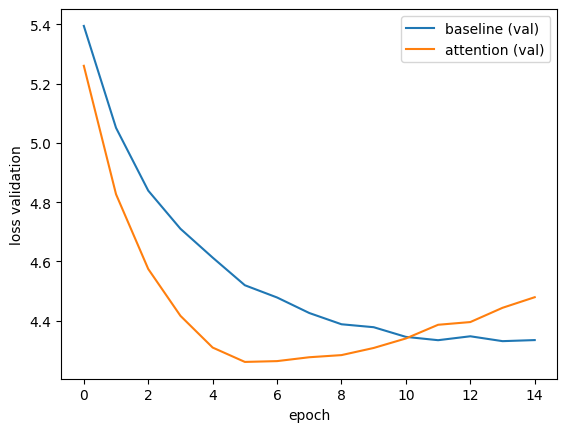

RÉFÉRENCE: Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.
BASELINE : hannah and zoe are going to the gym . .
ATTENTION: hannah and hannah are going to the . hannah is feeling well . hannah is feeling well . hannah is feeling well .
--------------------------------------------------
RÉFÉRENCE: Eric and Rob are going to watch a stand-up on youtube.
BASELINE : eric is to to to the . . . . .
ATTENTION: rob and rob are rob are going to the . rob rob rob rob on the . rob . rob are rob . rob . rob .
--------------------------------------------------
RÉFÉRENCE: Lenny can't decide which trousers to buy. Bob advised Lenny on that topic. Lenny goes with Bob's advice to pick the trousers that are of best quality.
BASELINE : bob has a the to the . .
ATTENTION: bob needs to help with bob . bob will bob to the . .
--------------------------------------------------
RÉFÉRENCE: Emma will be home soon and she will let Will know.
BASELINE : emma will going to to to wit

In [21]:
!pip install -q rouge-score
import time, matplotlib.pyplot as plt
from rouge_score import rouge_scorer

EPOCHS, TF_RATIO = 15, 0.5
criterion = nn.CrossEntropyLoss(ignore_index=PAD)
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"])
refs = dataset_samsum["test"]["summary"]

def run_epoch(model, loader, train, tf, opt=None):
    model.train(train)
    total = 0
    for src, src_len, tgt in loader:
        src, tgt = src.to(device), tgt.to(device)
        with torch.set_grad_enabled(train):
            out = model(src, src_len, tgt, tf)
            loss = criterion(out.reshape(-1, out.size(-1)), tgt[:, 1:].reshape(-1))
            if train:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
        total += loss.item()
    return total / len(loader)

def entrainer(model, nom):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    ht, hv, best = [], [], float("inf")
    for ep in range(1, EPOCHS + 1):
        t0 = time.time()
        tr = run_epoch(model, train_loader, True, TF_RATIO, opt)
        va = run_epoch(model, val_loader, False, 1.0)
        ht.append(tr); hv.append(va)
        if va < best:
            best = va; torch.save(model.state_dict(), nom + ".pt")
        print(f"{nom} | epoch {ep} | train {tr:.3f} | val {va:.3f} | {time.time()-t0:.0f}s")
    return ht, hv

@torch.no_grad()
def generer(model, texte, att):
    model.eval()
    ids = encoder_dialogue(texte)
    src = torch.tensor([ids]).to(device)
    src_len = torch.tensor([len(ids)])
    if att:
        enc_out, h = model.enc(src, src_len); mask = src != PAD
    else:
        h = model.enc(src, src_len)
    token = torch.tensor([SOS]).to(device)
    sortie = []
    for _ in range(MAX_TGT):
        if att: logits, h, _ = model.dec(token, h, enc_out, mask)
        else:   logits, h = model.dec(token, h)
        token = logits.argmax(1)
        if token.item() == EOS: break
        sortie.append(id_resume[token.item()])
    return " ".join(sortie)

def rouge_moyen(hyps):
    sc = [scorer.score(r, h) for r, h in zip(refs, hyps)]
    return {k: round(100 * sum(s[k].fmeasure for s in sc) / len(sc), 2) for k in ["rouge1", "rouge2", "rougeL"]}

res = {}
for nom, att in [("baseline", False), ("attention", True)]:
    if att: model = Seq2SeqAtt(EncoderAtt(len(vocab_dial)), DecoderAtt(len(vocab_resume))).to(device)
    else:   model = Seq2Seq(Encoder(len(vocab_dial)), Decoder(len(vocab_resume))).to(device)
    print(nom, "paramètres :", sum(p.numel() for p in model.parameters()))
    ht, hv = entrainer(model, nom)
    model.load_state_dict(torch.load(nom + ".pt"))
    hyps = [generer(model, d, att) for d in dataset_samsum["test"]["dialogue"]]
    res[nom] = dict(ht=ht, hv=hv, hyps=hyps, rouge=rouge_moyen(hyps))
    print(nom, "ROUGE :", res[nom]["rouge"])

for nom in res: plt.plot(res[nom]["hv"], label=nom + " (val)")
plt.xlabel("epoch"); plt.ylabel("loss validation"); plt.legend(); plt.show()

for i in range(5):
    print("RÉFÉRENCE:", refs[i])
    print("BASELINE :", res["baseline"]["hyps"][i])
    print("ATTENTION:", res["attention"]["hyps"][i])
    print("-" * 50)

**Résultats : courbes et scores**

On a entraîné les deux modèles pendant 15 epochs avec les mêmes réglages. La baseline a 6 597 897 paramètres et l’attention 9 320 201, soit environ 41 % de plus. L’attention est aussi beaucoup plus lente : environ 70 secondes par epoch contre 19 pour la baseline.

Sur la perte de validation, l’attention apprend plus vite et atteint son minimum à l’epoch 6 (4,260). La baseline descend plus doucement et se stabilise autour de 4,33 à partir de l’epoch 12 (minimum 4,331 à l’epoch 14). Mais ensuite, l’attention se met à surapprendre : sa perte de validation remonte jusqu’à 4,479 à l’epoch 15, alors que sa perte d’entraînement continue de baisser (2,711). Le modèle apprend les exemples du train par cœur. C’est pour ça qu’on a gardé les poids de l’epoch où la validation était la plus basse : pour l’attention, ce sont ceux de l’epoch 6.

Sur le test, les scores ROUGE sont les suivants. La baseline obtient 19,27 en ROUGE-1, 2,94 en ROUGE-2 et 17,02 en ROUGE-L. L’attention obtient 23,96, 5,53 et 20,85. L’attention est donc meilleure sur les trois scores, d’environ 4 à 5 points en ROUGE-1 et ROUGE-L, et elle double presque le ROUGE-2.

**Exemples générés et analyse des échecs**

Quand on lit les résumés, on voit que les deux modèles sont encore mauvais, même si les scores de l’attention sont meilleurs. Aucun ne produit un résumé correct sur les cinq exemples regardés.

La baseline écrit des phrases presque vides, avec beaucoup de « to the » et de points : par exemple « eric is to to to the . . . . . ». Elle reprend parfois un prénom du dialogue, mais invente le reste (« hannah and zoe are going to the gym » alors que le résumé parle de trouver le numéro de Betty).

L’attention reprend plus souvent les bons prénoms (rob, emma, ollie, bob), ce qui est cohérent avec le fait qu’elle regarde le dialogue. Mais elle se met à répéter : « hannah is feeling well . hannah is feeling well », « rob rob rob rob », « friday . friday ». Ces boucles viennent du décodage glouton : quand le modèle choisit un mot, il a tendance à se redonner le même mot ensuite, et rien ne l’en empêche.

On en tire trois causes principales. Le modèle est petit et entraîné de zéro sur seulement 14 731 exemples. Les prénoms rares sont remplacés par <UNK>, donc il ne peut pas toujours les recopier. Et les résumés de référence reformulent beaucoup, ce qui est difficile à apprendre.

Les dialogues les plus difficiles sont les longs, comme celui de Jane et Ollie (plusieurs événements dans un seul résumé), et ceux où l’information utile est répartie sur plusieurs messages.

**Discussion et conclusion**

Est-ce que le modèle apprend la tâche ? Un peu. Il apprend la forme d’un résumé (troisième personne, phrases courtes, prénoms du dialogue), mais pas encore le contenu. Les scores ROUGE sont faibles, surtout ROUGE-2 : un bon modèle sur SAMSum est bien plus haut. Ça reste normal pour un modèle fait de zéro, petit, entraîné quelques minutes.

Est-ce que l’attention aide ? Oui. Elle améliore les trois scores ROUGE et la perte de validation (4,260 contre 4,331), et elle reprend mieux les prénoms. Mais le gain est modeste sur la perte, il vient d’une seule expérience, et l’attention coûte plus de paramètres et beaucoup plus de temps de calcul.

Surapprentissage. Il est net pour l’attention après l’epoch 6, et léger pour la baseline après l’epoch 12. On l’a limité en gardant les meilleurs poids, mais on pourrait ajouter du dropout ou arrêter l’entraînement plus tôt.

Limites. Petit modèle, peu de données, vocabulaire limité (les mots rares deviennent <UNK>), décodage glouton qui répète, une seule expérience par modèle, et ROUGE qui compte les mots sans comprendre le sens.

Pistes d’amélioration. Un décodage par beam search avec pénalité de répétition, du dropout, des embeddings pré-entraînés, une tokenisation en sous-mots pour ne plus perdre les prénoms, et un mécanisme de copie pour recopier les mots du dialogue.

Conclusion. On a construit de bout en bout un système de résumé de dialogues : préparation des données, encodeur-décodeur GRU, attention, entraînement, génération et évaluation. L’attention améliore nettement les scores par rapport à la baseline, mais les résumés restent faibles, et les analyser nous a appris pourquoi.